# Atividade Prática 3 — 04 · Análises (Seção 2.1)

> **Este notebook só LÊ resultados** (`results/curvas/`, gravado pelo `03_Etapa2-Buscas.ipynb`, e `representations/`): não roda
> busca nem treino. Se faltar algum método, ele avisa qual. Tabelas vão para `results/tables/` e figuras para `results/figures/`.

**Métrica.** Para cada método, a perda da melhor configuração encontrada até a i-ésima avaliação, **normalizada por dataset entre
L\* e a pior perda da matriz**, média sobre datasets e sementes (é o ADTM do paper do D2V). **AUC** = média dessa curva em
i = 1..T (área normalizada). Também o **rank médio** entre os métodos a cada avaliação (a outra métrica do paper do D2V). Nos
testes, as sementes são agregadas pela média e os 120 datasets são os blocos.

In [1]:
import os, sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

ROOT = Path.cwd()
if not (ROOT / "src" / "config.py").exists():
    ROOT = Path(r"D:\Projetos\DisciplinaMtL\entrega3")
os.chdir(ROOT); sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src import config as cfg, search, analysis as an
from src.metatask_data import load_meta_task

an.setup_matplotlib()
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
cfg.make_dirs()

def save_fig(fig, name):
    for ext in ("png", "pdf"):
        fig.savefig(cfg.FIGURES_DIR / f"{name}.{ext}", bbox_inches="tight", facecolor="white")

def save_table(df, name, index=True):
    df.to_csv(cfg.TABLES_DIR / f"{name}.csv", index=index)

from scipy.stats import spearmanr, mannwhitneyu

meta = load_meta_task()
REPS = cfg.REP_ALL + cfg.REP_CONTROL                    # Random = controle (vizinhos arbitrários), só na Análise 2
ctx = search.build_context(meta, reps=REPS)            # vizinhos/distâncias LODO (rápido; não roda busca)
names, L, R = ctx["names"], ctx["L"], ctx["R"]
K, n = L.shape[1], L.shape[0]
KEYS = search.all_method_keys(REPS)
CURVES = an.load_curves(ctx, KEYS)                     # falha (dizendo o que falta) se o 03 não rodou algum método
ds_info = an.dataset_table(meta, L, ctx["default_idx"])
print(f"{len(CURVES)} métodos carregados | curvas {next(iter(CURVES.values())).shape} (alvos x sementes x T)")

22 métodos carregados | curvas (120, 5, 100) (alvos x sementes x T)


## Análise 1 — Curvas de perda

Comparação principal com **k = 1** no warm-start por similaridade (protocolo do paper do D2V, fixado a priori; k = 3, 5 na
Análise 2). Orçamentos: **t = 20** (logo após os pontos iniciais), **t = 50** (intermediário) e **t = T = 100**, além da AUC.

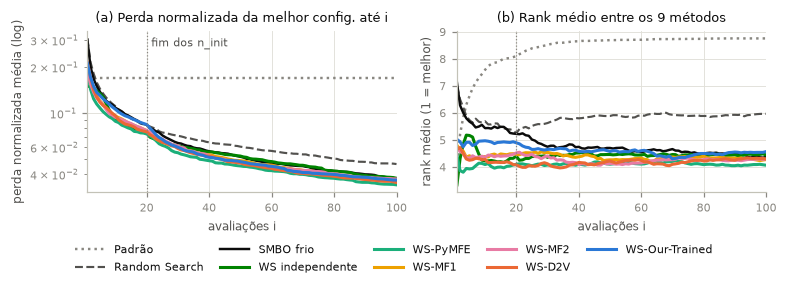

In [2]:
MAIN = ["default", "random_search", "smbo_cold", "smbo_ws_avgrank"] + [f"smbo_ws_{r}_k{cfg.K_MAIN}" for r in cfg.REP_ALL]
SHORT = {search.method_label(k): search.method_label(k).replace(f" (k={cfg.K_MAIN})", "") for k in MAIN}
main_curves = {k: CURVES[k] for k in MAIN}

mean_curves = pd.DataFrame({SHORT[search.method_label(k)]: an.per_dataset(c).mean(0) for k, c in main_curves.items()},
                           index=pd.RangeIndex(1, cfg.T_BUDGET + 1, name="i"))
rank_trial = an.average_rank_per_trial(main_curves, names).rename(columns=SHORT)
save_table(mean_curves, "analise1_curvas_media"); save_table(rank_trial, "analise1_rank_por_avaliacao")

fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.6))
for k in MAIN:
    lab = SHORT[search.method_label(k)]; st = an.style_of(k)
    axes[0].plot(mean_curves.index, mean_curves[lab], label=lab, **st)
    axes[1].plot(rank_trial.index, rank_trial[lab], label=lab, **st)
axes[0].set_yscale("log")
axes[0].set(xlabel="avaliações i", ylabel="perda normalizada média (log)", title="(a) Perda normalizada da melhor config. até i")
axes[1].set(xlabel="avaliações i", ylabel="rank médio (1 = melhor)", title="(b) Rank médio entre os 9 métodos")
for ax in axes:
    ax.axvline(cfg.N_INIT, color="#898781", lw=0.8, ls=":")
    ax.set_xlim(1, cfg.T_BUDGET)
axes[0].annotate("fim dos n_init", (cfg.N_INIT, 1), xycoords=("data", "axes fraction"), xytext=(3, -10),
                 textcoords="offset points", fontsize=7, color="#52514e")
fig.tight_layout(rect=(0, 0.13, 1, 1))
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=5, bbox_to_anchor=(0.5, 0.0), fontsize=7.5,
           handlelength=2.6, columnspacing=1.4)
save_fig(fig, "analise1_curvas"); plt.show()

In [3]:
summary1 = an.summary_table(main_curves, names).rename(index=SHORT).sort_values("AUC")
save_table(summary1, "analise1_resumo")
print("Perda normalizada média (alvos x sementes) em t = n_init, intermediário e T; AUC = média da curva em i = 1..T:")
display(summary1.style.format("{:.4f}", subset=[c for c in summary1.columns if c != "rank médio (AUC)"])
        .format("{:.2f}", subset=["rank médio (AUC)"]).highlight_min(color="#cde2fb"))

Perda normalizada média (alvos x sementes) em t = n_init, intermediário e T; AUC = média da curva em i = 1..T:


,t=20,t=50,t=100,AUC,rank médio (AUC)
WS-PyMFE,0.0733,0.0453,0.0341,0.0549,3.95
WS-D2V,0.0757,0.0475,0.0353,0.0581,4.01
WS-MF2,0.0773,0.0473,0.0373,0.0589,4.19
WS-MF1,0.0771,0.0491,0.0363,0.0593,4.35
WS independente,0.0755,0.0526,0.0377,0.0604,4.14
WS-Our-Trained,0.0845,0.0483,0.0367,0.0608,4.53
SMBO frio,0.0842,0.0520,0.0375,0.0652,5.40
Random Search,0.0834,0.0606,0.0467,0.0722,6.07
Padrão,0.1700,0.1700,0.1700,0.1700,8.36


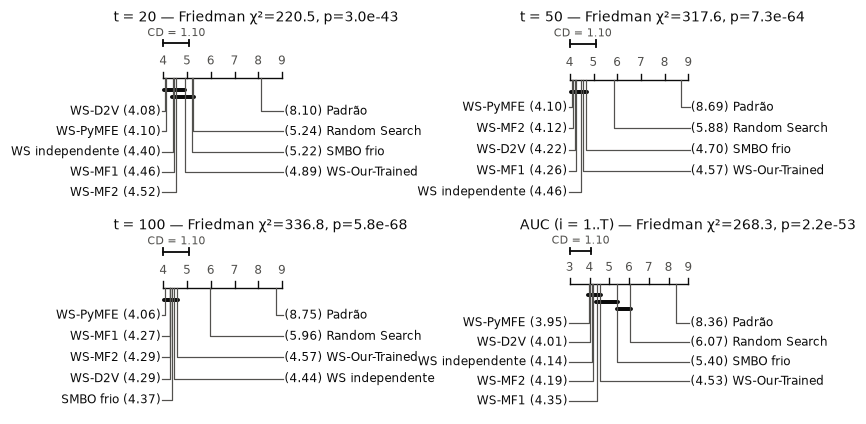

orçamento,t = 20,t = 50,t = 100,AUC (i = 1..T)
Friedman χ²,220.5369,317.6031,336.8342,268.3225
p,0.0000,0.0000,0.0000,0.0000
CD (Nemenyi),1.0966,1.0966,1.0966,1.0966
rank WS-D2V,4.0750,4.2167,4.2917,4.0125
rank WS-PyMFE,4.0958,4.1000,4.0625,3.9542
rank WS independente,4.4000,4.4583,4.4417,4.1375
rank WS-MF1,4.4625,4.2625,4.2708,4.3542
rank WS-MF2,4.5167,4.1208,4.2875,4.1917
rank WS-Our-Trained,4.8917,4.5708,4.5667,4.5250
rank SMBO frio,5.2208,4.7000,4.3667,5.4000


In [4]:
fig, axes = plt.subplots(2, 2, figsize=(7.4, 3.9))
tests1 = []
for ax, at in zip(axes.ravel(), [cfg.N_INIT, 50, cfg.T_BUDGET, "AUC"]):
    data = an.values_at(main_curves, names, at).rename(columns=SHORT)
    res = an.friedman_nemenyi(data)
    tag = f"t = {at}" if at != "AUC" else "AUC (i = 1..T)"
    an.plot_cd(res, ax, title=f"{tag} — Friedman χ²={res['friedman_stat']:.1f}, p={res['friedman_p']:.1e}")
    tests1.append({"orçamento": tag, "Friedman χ²": res["friedman_stat"], "p": res["friedman_p"], "CD (Nemenyi)": res["cd"],
                   **{f"rank {m}": v for m, v in res["ranks"].items()}})
fig.tight_layout(); save_fig(fig, "analise1_cd"); plt.show()
tests1 = pd.DataFrame(tests1).set_index("orçamento"); save_table(tests1, "analise1_friedman_nemenyi")
display(tests1.T.round(4))

In [5]:
# Wilcoxon pareado (Holm) dos warm-starts contra o SMBO frio e contra o WS independente, em cada orçamento
ws_main = [SHORT[search.method_label(f"smbo_ws_{r}_k{cfg.K_MAIN}")] for r in cfg.REP_ALL]
rows = []
for at in [cfg.N_INIT, 50, cfg.T_BUDGET, "AUC"]:
    data = an.values_at(main_curves, names, at).rename(columns=SHORT)
    pairs = [(w, "SMBO frio") for w in ws_main + ["WS independente"]] + [(w, "WS independente") for w in ws_main]
    pt = an.paired_tests(data, pairs); pt.insert(0, "orçamento", at); rows.append(pt)
pairs1 = pd.concat(rows, ignore_index=True); save_table(pairs1, "analise1_wilcoxon", index=False)
display(pairs1.round(4))

,orçamento,A,B,média A,média B,B − A,A melhor,empates,A pior,p (Wilcoxon),p (Holm),signif.
0,20,WS-PyMFE,SMBO frio,0.0733,0.0842,0.0109,74,11,35,0.0030,0.0327,True
1,20,WS-MF1,SMBO frio,0.0771,0.0842,0.0071,63,13,44,0.0930,0.7438,False
2,20,WS-MF2,SMBO frio,0.0773,0.0842,0.0068,60,14,46,0.1641,1.0000,False
3,20,WS-D2V,SMBO frio,0.0757,0.0842,0.0085,68,15,37,0.0041,0.0412,True
4,20,WS-Our-Trained,SMBO frio,0.0845,0.0842,-0.0004,59,15,46,0.4593,1.0000,False
5,20,WS independente,SMBO frio,0.0755,0.0842,0.0087,66,15,39,0.0065,0.0584,False
6,20,WS-PyMFE,WS independente,0.0733,0.0755,0.0022,51,27,42,0.4608,1.0000,False
7,20,WS-MF1,WS independente,0.0771,0.0755,-0.0015,47,25,48,0.8151,1.0000,False
8,20,WS-MF2,WS independente,0.0773,0.0755,-0.0018,48,25,47,0.5601,1.0000,False
9,20,WS-D2V,WS independente,0.0757,0.0755,-0.0002,47,38,35,0.6078,1.0000,False


## Análise 2 — O papel das meta-características

Método 4 contra o método 5 (o controle independente dos dados), para cada representação e **k ∈ {1, 3, 5}**. Como trocamos o
problema, a comparação X_base × X_estendido vira **clássicas (PyMFE, MF1, MF2) × aprendidas (D2V, Our-Trained)**. Um segundo
controle, **WS-Random (k)** — o método 4 com k datasets *arbitrários* —, separa o efeito de *juntar as melhores configurações de k
datasets* do efeito de *escolhê-los por similaridade*. Por fim, isolamos a fase inicial (sem SMBO).

In [6]:
ws_keys = [f"smbo_ws_{r}_k{k}" for r in REPS for k in cfg.K_NEIGHBORS]
rows2 = []
for at in [cfg.N_INIT, 50, cfg.T_BUDGET, "AUC"]:
    data = an.values_at({k: CURVES[k] for k in ws_keys + ["smbo_ws_avgrank", "smbo_cold"]}, names, at)
    pt = an.paired_tests(data, [(search.method_label(k), "WS independente") for k in ws_keys])
    pt.insert(0, "orçamento", at); rows2.append(pt)
tab2 = pd.concat(rows2, ignore_index=True); save_table(tab2, "analise2_ws_vs_independente", index=False)

piv = tab2.pivot_table(index="A", columns="orçamento", values="média A", sort=False)
piv.columns = [f"t={c}" if c != "AUC" else "AUC" for c in piv.columns]
ref = an.summary_table({k: CURVES[k] for k in ["smbo_ws_avgrank", "smbo_cold"]}, names)
piv = pd.concat([piv, ref[piv.columns]])
sig = tab2[tab2["orçamento"] == "AUC"].set_index("A")[["B − A", "A melhor", "A pior", "p (Holm)"]]
sig.columns = ["AUC: indep − WS", "WS melhor (alvos)", "WS pior (alvos)", "p Holm vs indep (AUC)"]
sig20 = tab2[tab2["orçamento"] == cfg.N_INIT].set_index("A")[["p (Holm)"]].rename(
    columns={"p (Holm)": f"p Holm vs indep (t={cfg.N_INIT})"})
table2 = piv.join(sig).join(sig20); save_table(table2, "analise2_resumo")
display(table2.style.format("{:.4f}", subset=[c for c in table2.columns if c.startswith(("t=", "AUC"))])
        .format("{:.3g}", subset=[c for c in table2.columns if c.startswith("p ")], na_rep="—"))

,t=20,t=50,t=100,AUC,AUC: indep − WS,WS melhor (alvos),WS pior (alvos),p Holm vs indep (AUC),p Holm vs indep (t=20)
WS-PyMFE (k=1),0.0733,0.0453,0.0341,0.0549,0.0055,65.000000,54.000000,1,1
WS-PyMFE (k=3),0.0635,0.0452,0.0338,0.0531,0.0072,67.000000,52.000000,0.843,0.4
WS-PyMFE (k=5),0.0645,0.0438,0.0326,0.0525,0.0079,68.000000,50.000000,0.259,0.75
WS-MF1 (k=1),0.0771,0.0491,0.0363,0.0593,0.0010,56.000000,61.000000,1,1
WS-MF1 (k=3),0.0670,0.0476,0.0365,0.0554,0.0049,72.000000,44.000000,0.299,0.4
WS-MF1 (k=5),0.0601,0.0431,0.0335,0.0515,0.0089,76.000000,40.000000,0.0971,0.00984
WS-MF2 (k=1),0.0773,0.0473,0.0373,0.0589,0.0015,59.000000,59.000000,1,1
WS-MF2 (k=3),0.0671,0.0474,0.0354,0.0550,0.0054,68.000000,50.000000,0.843,0.4
WS-MF2 (k=5),0.0616,0.0435,0.0336,0.0518,0.0086,71.000000,47.000000,0.259,0.0748
WS-D2V (k=1),0.0757,0.0475,0.0353,0.0581,0.0022,60.000000,58.000000,1,1


In [7]:
# Similaridade x vizinhos arbitrários: WS-<rep>(k) contra WS-Random(k), mesmo k (Wilcoxon pareado, Holm)
rows = []
for at in [cfg.N_INIT, "AUC"]:
    for k in cfg.K_NEIGHBORS:
        keys = [f"smbo_ws_{r}_k{k}" for r in REPS]
        data = an.values_at({kk: CURVES[kk] for kk in keys}, names, at)
        pt = an.paired_tests(data, [(search.method_label(f"smbo_ws_{r}_k{k}"), search.method_label(f"smbo_ws_Random_k{k}"))
                                    for r in cfg.REP_ALL])
        pt.insert(0, "orçamento", at); rows.append(pt)
vs_random = pd.concat(rows, ignore_index=True)
vs_random["p (Holm)"] = an.multipletests(vs_random["p (Wilcoxon)"], method="holm")[1]   # Holm sobre todas as 30 comparações
vs_random["signif."] = vs_random["p (Holm)"] < an.ALPHA
save_table(vs_random, "analise2_ws_vs_random", index=False)
display(vs_random.round(4))

,orçamento,A,B,média A,média B,B − A,A melhor,empates,A pior,p (Wilcoxon),p (Holm),signif.
0,20,WS-PyMFE (k=1),WS-Random (k=1),0.0733,0.0817,0.0084,57,22,41,0.0677,1.0000,False
1,20,WS-MF1 (k=1),WS-Random (k=1),0.0771,0.0817,0.0046,55,19,46,0.2557,1.0000,False
2,20,WS-MF2 (k=1),WS-Random (k=1),0.0773,0.0817,0.0043,55,22,43,0.3369,1.0000,False
3,20,WS-D2V (k=1),WS-Random (k=1),0.0757,0.0817,0.0060,60,30,30,0.0355,0.7459,False
4,20,WS-Our-Trained (k=1),WS-Random (k=1),0.0845,0.0817,-0.0029,50,21,49,0.9028,1.0000,False
5,20,WS-PyMFE (k=3),WS-Random (k=3),0.0635,0.0723,0.0087,60,21,39,0.0212,0.4886,False
6,20,WS-MF1 (k=3),WS-Random (k=3),0.0670,0.0723,0.0052,56,22,42,0.2155,1.0000,False
7,20,WS-MF2 (k=3),WS-Random (k=3),0.0671,0.0723,0.0051,60,19,41,0.1573,1.0000,False
8,20,WS-D2V (k=3),WS-Random (k=3),0.0667,0.0723,0.0055,51,19,50,0.7708,1.0000,False
9,20,WS-Our-Trained (k=3),WS-Random (k=3),0.0689,0.0723,0.0034,54,21,45,0.3642,1.0000,False


In [8]:
# Fase inicial isolada (sem SMBO): perda após os n_init pontos em função de k = 1..20, e oráculo (melhor vizinho, k = 1)
orders = an.config_orders(L, cfg.N_SEEDS)
init_k = {rep: an.init_regret_vs_k(ctx, orders, rep) for rep in REPS}
M = an.transfer_matrix(ctx, orders)            # M[i, j]: perda em i com as 20 melhores configurações de j
indep_init = an.per_dataset(CURVES["smbo_ws_avgrank"])[:, cfg.N_INIT - 1].mean()
cold_init = an.per_dataset(CURVES["smbo_cold"])[:, cfg.N_INIT - 1].mean()
init_k_df = pd.DataFrame({rep: df.mean() for rep, df in init_k.items()}); init_k_df.index.name = "k"
save_table(init_k_df, "analise2_fase_inicial_por_k")
display(init_k_df.loc[[1, 2, 3, 5, 10, 20]].round(4))

quality = an.neighbor_quality(ctx, M, REPS)
quality.loc["WS independente", "perda após n_init (vizinho escolhido)"] = indep_init
quality.loc["SMBO frio (20 aleatórias)", "perda após n_init (vizinho escolhido)"] = cold_init
save_table(quality, "analise2_qualidade_vizinho")
display(quality.round(4))

,PyMFE,MF1,MF2,D2V,Our-Trained,Random
k,,,,,,
1,0.0698,0.0798,0.0785,0.0737,0.0838,0.0802
2,0.0620,0.0718,0.0707,0.0664,0.0783,0.0778
3,0.0649,0.0687,0.0688,0.0675,0.0693,0.0715
5,0.0644,0.0616,0.0604,0.0643,0.0640,0.0735
10,0.0646,0.0621,0.0624,0.0627,0.0650,0.0716
20,0.0665,0.0654,0.0647,0.0633,0.0639,0.0678


,perda após n_init (vizinho escolhido),percentil do vizinho (0 = melhor),"ρ(distância, perda transferida) médio",p (Wilcoxon ρ ≠ 0)
PyMFE,0.0698,42.1045,0.0104,0.5466
MF1,0.0798,48.4322,0.0102,0.4692
MF2,0.0785,47.6836,0.0094,0.5020
D2V,0.0737,44.1243,0.0603,0.0002
Our-Trained,0.0838,51.6455,-0.0104,0.3006
Random,0.0802,52.1540,0.0195,0.0283
Oráculo (melhor vizinho),0.0078,0.0000,NaN,NaN
Vizinho aleatório,0.0779,50.0000,NaN,NaN
WS independente,0.0755,NaN,NaN,NaN
SMBO frio (20 aleatórias),0.0842,NaN,NaN,NaN


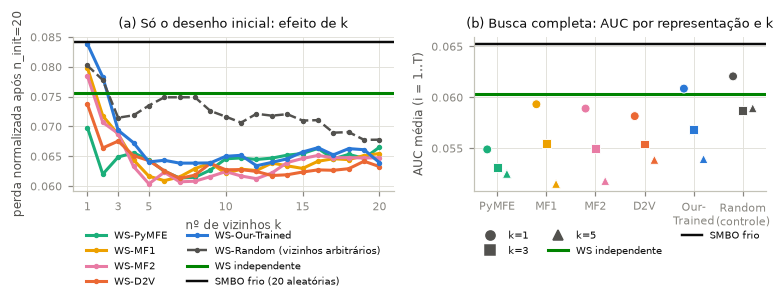

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.9), gridspec_kw={"width_ratios": [1.1, 1]})
ax = axes[0]
for rep in REPS:
    ctrl = rep in cfg.REP_CONTROL
    ax.plot(init_k_df.index, init_k_df[rep], color=an.REP_COLORS[rep], lw=1.6 if ctrl else 2, ls="--" if ctrl else "-",
            marker="o", ms=2.5, label=f"WS-{rep}" + (" (vizinhos arbitrários)" if ctrl else ""))
ax.axhline(indep_init, label="WS independente", **an.FIXED_STYLE["smbo_ws_avgrank"])
ax.axhline(cold_init, label="SMBO frio (20 aleatórias)", **an.FIXED_STYLE["smbo_cold"])
ax.set(xlabel="nº de vizinhos k", ylabel=f"perda normalizada após n_init={cfg.N_INIT}",
       title="(a) Só o desenho inicial: efeito de k", xticks=[1, 3, 5, 10, 15, 20])
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2, fontsize=6.5)

ax = axes[1]
xs = np.arange(len(REPS))
for j, k in enumerate(cfg.K_NEIGHBORS):
    vals = [an.auc(CURVES[f"smbo_ws_{r}_k{k}"]).mean() for r in REPS]
    ax.scatter(xs + (j - 1) * 0.2, vals, s=34, marker=["o", "s", "^"][j], color=[an.REP_COLORS[r] for r in REPS],
               edgecolor="white", linewidth=0.6, zorder=3)
ax.axhline(an.auc(CURVES["smbo_ws_avgrank"]).mean(), **an.FIXED_STYLE["smbo_ws_avgrank"])
ax.axhline(an.auc(CURVES["smbo_cold"]).mean(), **an.FIXED_STYLE["smbo_cold"])
tick = {"Our-Trained": "Our-\nTrained", **{r: f"{r}\n(controle)" for r in cfg.REP_CONTROL}}
ax.set_xticks(xs, [tick.get(r, r) for r in REPS], fontsize=7)
ax.set(ylabel="AUC média (i = 1..T)", title="(b) Busca completa: AUC por representação e k")
handles = [plt.Line2D([], [], marker=m, color="#52514e", ls="", label=f"k={k}") for m, k in zip(["o", "s", "^"], cfg.K_NEIGHBORS)]
handles += [plt.Line2D([], [], label="WS independente", **an.FIXED_STYLE["smbo_ws_avgrank"]),
            plt.Line2D([], [], label="SMBO frio", **an.FIXED_STYLE["smbo_cold"])]
ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3, fontsize=6.5)
fig.tight_layout(); save_fig(fig, "analise2_meta_caracteristicas"); plt.show()

In [10]:
# Clássicas x aprendidas (k = K_MAIN): AUC média de cada família por alvo e teste pareado
fam = pd.DataFrame({"aprendidas": np.mean([an.auc(CURVES[f"smbo_ws_{r}_k{cfg.K_MAIN}"]) for r in cfg.REP_LEARNED], axis=0),
                    "clássicas": np.mean([an.auc(CURVES[f"smbo_ws_{r}_k{cfg.K_MAIN}"]) for r in cfg.REP_CLASSIC], axis=0)},
                   index=names)
display(an.paired_tests(fam, [("aprendidas", "clássicas")]).round(4))
# As representações escolhem os mesmos vizinhos?
nn1 = pd.DataFrame({rep: ctx["neighbors"][rep][:, 0] for rep in cfg.REP_ALL}, index=names)
agree = pd.DataFrame({a: {b: (nn1[a] == nn1[b]).mean() for b in cfg.REP_ALL} for a in cfg.REP_ALL})
print("Fração de alvos em que duas representações escolhem o MESMO vizinho mais próximo:"); display(agree.round(2))

,A,B,média A,média B,B − A,A melhor,empates,A pior,p (Wilcoxon),p (Holm),signif.
0,aprendidas,clássicas,0.0595,0.0577,-0.0018,55,0,65,0.3391,0.3391,False


Fração de alvos em que duas representações escolhem o MESMO vizinho mais próximo:


,PyMFE,MF1,MF2,D2V,Our-Trained
PyMFE,1.00,0.22,0.22,0.18,0.11
MF1,0.22,1.00,0.65,0.05,0.03
MF2,0.22,0.65,1.00,0.05,0.02
D2V,0.18,0.05,0.05,1.00,0.12
Our-Trained,0.11,0.03,0.02,0.12,1.00


## Análise 3 — Quando o warm-start falha

Ganho do método 4 sobre o método 3 por alvo: **ganho = AUC(SMBO frio) − AUC(WS-⟨rep⟩, k=1)** (> 0: o warm-start ajudou),
relacionado à distância de d_t ao vizinho mais próximo. Como as escalas das distâncias diferem entre representações, o gráfico
usa a **distância relativa** d_NN / mediana das distâncias de d_t aos 119 (perto de 0 = um vizinho que se destaca; perto de 1 =
vizinho indistinto); a tabela traz também a distância absoluta. Para explicar as falhas usamos a **similaridade "verdadeira"**
entre alvo e vizinho: o ρ de Spearman entre as perdas das 3456 configurações nos dois datasets.

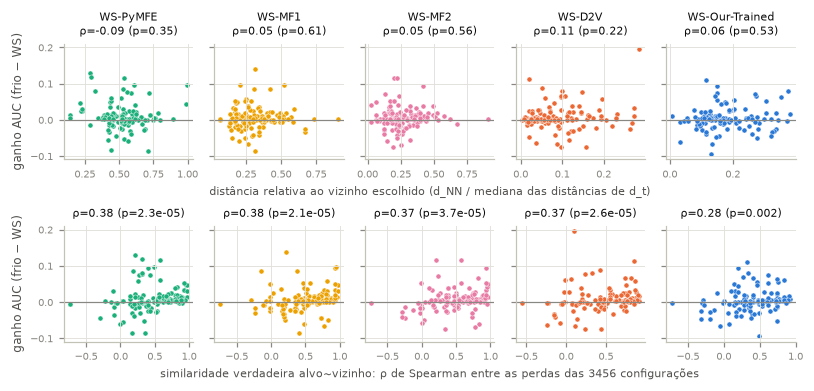

representação,PyMFE,MF1,MF2,D2V,Our-Trained
"ρ(ganho, dist. relativa)",-0.086895,0.047566,0.053663,0.11232,0.058226
p,0.345318,0.605927,0.560486,0.221935,0.527585
"ρ(ganho, dist. absoluta)",-0.12524,0.105394,0.101696,0.018321,0.13285
p (abs),0.172898,0.251943,0.269061,0.842567,0.14804
WS melhor,82,76,82,79,76
empate,0,0,0,0,0
WS pior,38,44,38,41,44
"ρ(ganho, ρ paisagem)",0.376339,0.37799,0.367274,0.373559,0.279077
"ρ(ganho, perda após n_init WS)",-0.272634,-0.346159,-0.213289,-0.3537,-0.274065
ρ paisagem alvo~vizinho: pior | melhor,0.266 | 0.642 (p=1.6e-08),0.347 | 0.687 (p=6e-07),0.332 | 0.667 (p=1.6e-06),0.224 | 0.716 (p=3.4e-08),0.317 | 0.596 (p=6.4e-05)


In [11]:
S_land = an.landscape_similarity(L)                  # ρ de Spearman entre as perdas das K configs de cada par de datasets
easy = ds_info["frac. configs no ótimo"].to_numpy()
auc_cold = an.auc(CURVES["smbo_cold"])
init_cold = an.per_dataset(CURVES["smbo_cold"])[:, cfg.N_INIT - 1]
fig, axes = plt.subplots(2, len(cfg.REP_ALL), figsize=(7.4, 3.6), sharey=True)
gain_rows, fail_tabs = [], {}
for c, rep in enumerate(cfg.REP_ALL):
    key = f"smbo_ws_{rep}_k{cfg.K_MAIN}"
    gain = auc_cold - an.auc(CURVES[key])
    nb_, dist = ctx["neighbors"][rep], ctx["distances"][rep]
    rel = dist[:, 0] / np.median(dist, axis=1)
    rho, p = spearmanr(rel, gain)
    rho_abs, p_abs = spearmanr(dist[:, 0], gain)
    nn = nb_[:, 0]
    land = S_land[np.arange(n), nn]
    rho_l, p_l = spearmanr(land, gain)
    for r, (x, rr, pp) in enumerate([(rel, rho, p), (land, rho_l, p_l)]):
        ax = axes[r, c]
        ax.axhline(0, color="#898781", lw=0.8)
        ax.scatter(x, gain, s=11, color=an.REP_COLORS[rep], edgecolor="white", linewidth=0.3)
        ax.set_title((f"WS-{rep}\n" if r == 0 else "") + f"ρ={rr:.2f} (p={pp:.2g})", fontsize=7.5)
        ax.tick_params(labelsize=6.5)
    init_ws = an.per_dataset(CURVES[key])[:, cfg.N_INIT - 1]
    df = pd.DataFrame({"ganho AUC": gain, "dist. relativa NN": rel, "vizinho": [names[j] for j in nn],
                       "ρ paisagem alvo~vizinho": land, "melhor ρ paisagem possível": np.nanmax(S_land, axis=1),
                       "perda após n_init (WS)": init_ws, "perda após n_init (frio)": init_cold,
                       "frac. configs no ótimo": easy, "n_instancias": ds_info["n_instancias"].to_numpy(),
                       "n_classes": ds_info["n_classes"].to_numpy()}, index=names)
    fail_tabs[rep] = df
    worse, better = df[df["ganho AUC"] < -1e-9], df[df["ganho AUC"] > 1e-9]
    row = {"representação": rep, "ρ(ganho, dist. relativa)": rho, "p": p, "ρ(ganho, dist. absoluta)": rho_abs,
           "p (abs)": p_abs, "WS melhor": len(better), "empate": n - len(better) - len(worse), "WS pior": len(worse),
           "ρ(ganho, ρ paisagem)": spearmanr(land, gain).statistic,
           "ρ(ganho, perda após n_init WS)": spearmanr(init_ws, gain).statistic}
    for col in ["ρ paisagem alvo~vizinho", "frac. configs no ótimo", "perda após n_init (WS)", "n_instancias"]:
        p_mw = mannwhitneyu(worse[col], better[col]).pvalue if len(worse) and len(better) else np.nan
        row[f"{col}: pior | melhor"] = f"{worse[col].median():.3g} | {better[col].median():.3g} (p={p_mw:.2g})"
    gain_rows.append(row)
axes[0, 0].set_ylabel("ganho AUC (frio − WS)"); axes[1, 0].set_ylabel("ganho AUC (frio − WS)")
mid = len(cfg.REP_ALL) // 2
axes[0, mid].set_xlabel("distância relativa ao vizinho escolhido (d_NN / mediana das distâncias de d_t)", fontsize=7.5)
axes[1, mid].set_xlabel("similaridade verdadeira alvo~vizinho: ρ de Spearman entre as perdas das 3456 configurações",
                        fontsize=7.5)
fig.tight_layout(h_pad=0.8); save_fig(fig, "analise3_ganho_vs_distancia"); plt.show()
gain_tab = pd.DataFrame(gain_rows).set_index("representação"); save_table(gain_tab, "analise3_ganho_vs_distancia")
display(gain_tab.T)

In [12]:
# Alvos em que o warm-start foi pior do que partir do zero (os 10 piores, para três representações)
for rep in ["Our-Trained", "D2V", "PyMFE"]:
    df = fail_tabs[rep].sort_values("ganho AUC")
    save_table(df, f"analise3_por_alvo_{rep}")
    print(f"\nWS-{rep}: 10 alvos com MENOR ganho (negativo = pior que o SMBO frio)")
    display(df.head(10).round(4))


WS-Our-Trained: 10 alvos com MENOR ganho (negativo = pior que o SMBO frio)


,ganho AUC,dist. relativa NN,vizinho,ρ paisagem alvo~vizinho,melhor ρ paisagem possível,perda após n_init (WS),perda após n_init (frio),frac. configs no ótimo,n_instancias,n_classes
heart-switzerland,-0.0940,0.1309,conn-bench-vowel-deterding,0.4947,0.5182,0.3846,0.1692,0.0003,123,5
wine-quality-white,-0.0655,0.1340,post-operative,-0.0546,0.8121,0.2778,0.1717,0.0003,4898,7
post-operative,-0.0608,0.0319,magic,0.0654,0.4825,0.1000,0.0600,0.0049,90,3
primary-tumor,-0.0511,0.2771,led-display,0.7417,0.7733,0.2000,0.2074,0.0012,330,15
hayes-roth,-0.0473,0.1467,haberman-survival,-0.1982,0.7206,0.2500,0.0875,0.0069,160,3
cardiotocography-3clases,-0.0456,0.1550,bank,-0.3176,0.9227,0.2363,0.1088,0.0003,2126,3
parkinsons,-0.0450,0.3221,heart-hungarian,0.3842,0.7884,0.0952,0.0381,0.0026,195,2
lung-cancer,-0.0385,0.1155,waveform-noise,0.1630,0.3830,0.2500,0.0000,0.0897,32,3
pima,-0.0380,0.2601,car,0.2409,0.6373,0.1623,0.0831,0.0009,768,2
monks-1,-0.0336,0.1164,monks-3,0.3993,0.5905,0.3218,0.1740,0.0023,556,2



WS-D2V: 10 alvos com MENOR ganho (negativo = pior que o SMBO frio)


,ganho AUC,dist. relativa NN,vizinho,ρ paisagem alvo~vizinho,melhor ρ paisagem possível,perda após n_init (WS),perda após n_init (frio),frac. configs no ótimo,n_instancias,n_classes
heart-switzerland,-0.0743,0.0976,flags,0.4382,0.5182,0.4154,0.1692,0.0003,123,5
cylinder-bands,-0.0733,0.1576,echocardiogram,0.2371,0.8036,0.3000,0.1667,0.0009,512,2
monks-2,-0.0668,0.0878,molec-biol-promoter,0.1108,0.4972,0.2308,0.1769,0.0029,601,2
breast-cancer-wisc-prog,-0.0638,0.0361,oocytes_merluccius_nucleus_4d,-0.2388,0.3397,0.2364,0.1273,0.0058,198,2
heart-va,-0.0564,0.1161,post-operative,-0.0757,0.4693,0.4083,0.3083,0.0003,200,5
pima,-0.0477,0.0208,magic,0.1420,0.6373,0.1849,0.0831,0.0009,768,2
congressional-voting,-0.0401,0.0837,miniboone,-0.1407,0.4305,0.2666,0.1601,0.0003,435,2
post-operative,-0.0352,0.1151,lung-cancer,-0.1502,0.4825,0.1000,0.0600,0.0049,90,3
lung-cancer,-0.0315,0.1205,post-operative,-0.1502,0.3830,0.2500,0.0000,0.0897,32,3
lymphography,-0.0314,0.1252,primary-tumor,0.5903,0.7075,0.1250,0.1125,0.0006,148,4



WS-PyMFE: 10 alvos com MENOR ganho (negativo = pior que o SMBO frio)


,ganho AUC,dist. relativa NN,vizinho,ρ paisagem alvo~vizinho,melhor ρ paisagem possível,perda após n_init (WS),perda após n_init (frio),frac. configs no ótimo,n_instancias,n_classes
lung-cancer,-0.0855,0.7140,molec-biol-promoter,0.1624,0.3830,0.2500,0.0000,0.0897,32,3
cylinder-bands,-0.0837,0.4417,heart-hungarian,0.3517,0.8036,0.3333,0.1667,0.0009,512,2
post-operative,-0.0592,0.5674,breast-cancer,-0.0118,0.4825,0.1000,0.0600,0.0049,90,3
echocardiogram,-0.0555,0.4220,heart-hungarian,0.0364,0.3809,0.2308,0.0769,0.0023,131,2
contrac,-0.0515,0.5335,heart-cleveland,0.3490,0.8018,0.1550,0.0929,0.0003,1473,3
parkinsons,-0.0432,0.4778,breast-cancer-wisc-prog,-0.2941,0.7884,0.0952,0.0381,0.0026,195,2
lymphography,-0.0381,0.5886,heart-cleveland,0.1936,0.7075,0.1875,0.1125,0.0006,148,4
ilpd-indian-liver,-0.0345,0.4239,pima,-0.0970,0.3178,0.2121,0.1394,0.0003,583,2
balloons,-0.0295,0.5798,tic-tac-toe,0.1650,0.2315,0.1500,0.1500,0.0362,16,2
lenses,-0.0290,0.6827,pittsburg-bridges-MATERIAL,0.2916,0.3542,0.1500,0.0000,0.0871,24,3


In [13]:
# A falha depende do alvo ou da representação?
G = pd.DataFrame({rep: fail_tabs[rep]["ganho AUC"] for rep in cfg.REP_ALL})
all_worse = G[(G < -1e-9).all(axis=1)]
print(f"{len(all_worse)} alvos em que os 5 warm-starts por similaridade (k=1) perdem para o SMBO frio:")
display(all_worse.join(ds_info[["n_instancias", "n_classes", "frac. configs no ótimo", "L*"]]).round(4))
save_table(all_worse, "analise3_falham_com_todas")
print("Correlação de Spearman entre os ganhos das representações:")
display(G.corr(method="spearman").round(2))

10 alvos em que os 5 warm-starts por similaridade (k=1) perdem para o SMBO frio:


,PyMFE,MF1,MF2,D2V,Our-Trained,n_instancias,n_classes,frac. configs no ótimo,L*
contrac,-0.0515,-0.0432,-0.0396,-0.0230,-0.0245,1473,3,0.0003,0.3558
echocardiogram,-0.0555,-0.0137,-0.0498,-0.0038,-0.0080,131,2,0.0023,0.0000
heart-switzerland,-0.0149,-0.0852,-0.0251,-0.0743,-0.0940,123,5,0.0003,0.1875
lung-cancer,-0.0855,-0.0250,-0.0110,-0.0315,-0.0385,32,3,0.0897,0.0000
mammographic,-0.0115,-0.0054,-0.0135,-0.0008,-0.0291,961,2,0.0003,0.1042
monks-1,-0.0248,-0.0278,-0.0036,-0.0252,-0.0336,556,2,0.0023,0.0312
parkinsons,-0.0432,-0.0589,-0.0397,-0.0096,-0.0450,195,2,0.0026,0.0625
pittsburg-bridges-MATERIAL,-0.0099,-0.0191,-0.0134,-0.0187,-0.0110,106,3,0.0153,0.1250
post-operative,-0.0592,-0.0322,-0.0172,-0.0352,-0.0608,90,3,0.0049,0.2308
vertebral-column-2clases,-0.0029,-0.0173,-0.0159,-0.0038,-0.0071,310,2,0.0003,0.0208


Correlação de Spearman entre os ganhos das representações:


,PyMFE,MF1,MF2,D2V,Our-Trained
PyMFE,1.00,0.48,0.51,0.41,0.42
MF1,0.48,1.00,0.67,0.39,0.27
MF2,0.51,0.67,1.00,0.41,0.41
D2V,0.41,0.39,0.41,1.00,0.42
Our-Trained,0.42,0.27,0.41,0.42,1.00


## O preço de restringir a busca às K configurações

Com a matriz completa a busca é simulada e L\* é exato — mas só **dentro do grid**. Alguns indícios do que isso esconde:

In [14]:
found = pd.DataFrame({SHORT[search.method_label(k)]: {
    "alvos com o ótimo do grid achado até T (%)": 100 * (an.per_dataset(CURVES[k])[:, -1] <= 1e-12).mean(),
    "avaliações até o ótimo (mediana, quando acha)": np.nanmedian(np.where(
        (CURVES[k] <= 1e-12).any(-1), (CURVES[k] > 1e-12).sum(-1) + 1, np.nan))} for k in MAIN}).T
save_table(found, "restricao_K_otimo_achado"); display(found.round(1))
print(f"Resolução da perda: mediana de {int(ds_info['valores distintos de perda'].median())} valores distintos entre as "
      f"{K} configurações; em {int((ds_info['frac. configs no ótimo'] >= 0.01).sum())} datasets >= 1% das configurações "
      f"empatam no ótimo.")
Yt = meta.Y_test.astype(float)
best_val = L.argmin(1)
test_gap = Yt.max(1) - Yt[np.arange(n), best_val]
rho_vt = np.array([spearmanr(L[i], 1 - Yt[i]).statistic for i in range(n)])
print(f"Validação x teste: escolher o ótimo de VALIDAÇÃO custa, em acurácia de teste, mediana {np.median(test_gap):.3f} "
      f"(média {test_gap.mean():.3f}) em relação ao ótimo de teste; ρ de Spearman médio entre as perdas de validação e de teste "
      f"das K configurações = {np.nanmean(rho_vt):.2f}.")

,alvos com o ótimo do grid achado até T (%),"avaliações até o ótimo (mediana, quando acha)"
Padrão,5.8,1.0
Random Search,12.5,15.0
SMBO frio,10.8,26.0
WS independente,18.3,16.0
WS-PyMFE,19.2,23.0
WS-MF1,16.7,19.0
WS-MF2,19.2,17.0
WS-D2V,17.5,21.0
WS-Our-Trained,15.8,26.5


Resolução da perda: mediana de 44 valores distintos entre as 3456 configurações; em 18 datasets >= 1% das configurações empatam no ótimo.
Validação x teste: escolher o ótimo de VALIDAÇÃO custa, em acurácia de teste, mediana 0.043 (média 0.085) em relação ao ótimo de teste; ρ de Spearman médio entre as perdas de validação e de teste das K configurações = 0.72.


## Arquivos gerados

In [15]:
for sub in ["tables", "figures"]:
    files = sorted((cfg.RESULTS_DIR / sub).glob("*"))
    print(f"results/{sub}/ ({len(files)}):", ", ".join(f.name for f in files))

results/tables/ (22): analise1_curvas_media.csv, analise1_friedman_nemenyi.csv, analise1_rank_por_avaliacao.csv, analise1_resumo.csv, analise1_wilcoxon.csv, analise2_fase_inicial_por_k.csv, analise2_qualidade_vizinho.csv, analise2_resumo.csv, analise2_ws_vs_independente.csv, analise2_ws_vs_random.csv, analise3_falham_com_todas.csv, analise3_ganho_vs_distancia.csv, analise3_por_alvo_D2V.csv, analise3_por_alvo_Our-Trained.csv, analise3_por_alvo_PyMFE.csv, buscas_conferencia.csv, datasets_resumo.csv, our_trained_ce_vs_prior.csv, our_trained_treino.csv, representacoes_dimensoes.csv, restricao_K_otimo_achado.csv, vizinho_mais_proximo_por_representacao.csv
results/figures/ (12): analise1_cd.pdf, analise1_cd.png, analise1_curvas.pdf, analise1_curvas.png, analise2_meta_caracteristicas.pdf, analise2_meta_caracteristicas.png, analise3_ganho_vs_distancia.pdf, analise3_ganho_vs_distancia.png, etapa1_meta_dados.pdf, etapa1_meta_dados.png, our_trained_treino.pdf, our_trained_treino.png
